# Trabalho Prático — Tópicos de Big Data em Python
**Aluno:** Jonathan Monteiro Henriques  
**Stack:** Pandas, Matplotlib, PySpark, scikit-learn

## 1. Inspeção inicial

In [ ]:
import os
import warnings
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
os.makedirs("resultado", exist_ok=True)

ARQUIVO = "vendas_bigdata_2026.csv"
df = pd.read_csv(ARQUIVO)
df.head()

In [2]:
df.shape

(1200, 15)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   pedido_id            1200 non-null   str    
 1   data                 1199 non-null   str    
 2   cliente_id           1200 non-null   str    
 3   categoria            1192 non-null   str    
 4   produto              1200 non-null   str    
 5   regiao               1188 non-null   str    
 6   canal                1200 non-null   str    
 7   forma_pagamento      1200 non-null   str    
 8   quantidade           1200 non-null   int64  
 9   preco_unitario       1200 non-null   float64
 10  desconto_percentual  1200 non-null   int64  
 11  valor                1200 non-null   float64
 12  frete                1200 non-null   float64
 13  avaliacao            854 non-null    float64
 14  devolvido            1200 non-null   str    
dtypes: float64(4), int64(2), str(9)
memory usage: 140

In [4]:
df.dtypes

pedido_id                  str
data                       str
cliente_id                 str
categoria                  str
produto                    str
regiao                     str
canal                      str
forma_pagamento            str
quantidade               int64
preco_unitario         float64
desconto_percentual      int64
valor                  float64
frete                  float64
avaliacao              float64
devolvido                  str
dtype: object

In [5]:
df.isna().sum()

pedido_id                0
data                     1
cliente_id               0
categoria                8
produto                  0
regiao                  12
canal                    0
forma_pagamento          0
quantidade               0
preco_unitario           0
desconto_percentual      0
valor                    0
frete                    0
avaliacao              346
devolvido                0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(8)

**Quantos registros existem?** 1.200 registros e 15 colunas.

**Problemas de qualidade identificados:**
- 8 linhas duplicadas (mesmo `pedido_id` repetido, linhas idênticas);
- datas inválidas (`2026-02-30`, `31/11/2026`, `2026-13-05`, `data_invalida`) e 1 data ausente;
- `regiao` com 12 ausentes e grafias inconsistentes (`sudeste`, ` Sudeste `, `CENTRO-OESTE`...);
- 8 ausentes em `categoria` e 346 em `avaliacao` (esta é natural: nem todo cliente avalia);
- 5 registros com `quantidade <= 0` e 5 com `preco_unitario <= 0`;
- registros em que `valor` não bate com `quantidade * preco_unitario * (1 - desconto/100)`.

**Dados primários ou secundários?** São **secundários**: não fui eu quem os coletou. Eles foram gerados por outro agente (a empresa, em seu sistema de vendas) e disponibilizados para a análise. Dados primários seriam os coletados por mim para este fim, por exemplo com uma pesquisa ou um experimento.

## 2. Preparação e qualidade dos dados

In [7]:

dados = df.copy()


print("Duplicatas completas:", dados.duplicated().sum())
dados = dados.drop_duplicates().copy()


dados["data"] = pd.to_datetime(dados["data"], errors="coerce")
mask_data_invalida = dados["data"].isna()
print("Datas inválidas/ausentes:", mask_data_invalida.sum())
dados.loc[mask_data_invalida, ["pedido_id", "data"]]

Duplicatas completas: 8
Datas inválidas/ausentes: 5


,pedido_id,data
237,PED000543,NaT
417,PED000669,NaT
470,PED000772,NaT
713,PED000808,NaT
1110,PED000379,NaT


In [8]:

df.loc[pd.to_datetime(df["data"], errors="coerce").isna(), ["pedido_id", "data"]]

,pedido_id,data
237,PED000543,NaN
417,PED000669,2026-02-30
470,PED000772,31/11/2026
713,PED000808,data_invalida
1110,PED000379,2026-13-05


In [9]:

print(dados.isna().sum())


print("Antes:", sorted(dados["regiao"].dropna().unique()))
dados["regiao"] = dados["regiao"].str.strip().str.title()
dados["regiao"] = dados["regiao"].fillna("Não informado")
dados["categoria"] = dados["categoria"].fillna("Não informado")
print("Depois:", sorted(dados["regiao"].unique()))

pedido_id                0
data                     5
cliente_id               0
categoria                8
produto                  0
regiao                  12
canal                    0
forma_pagamento          0
quantidade               0
preco_unitario           0
desconto_percentual      0
valor                    0
frete                    0
avaliacao              343
devolvido                0
dtype: int64
Antes: [' Nordeste ', ' Norte ', ' Sudeste ', ' Sul ', 'CENTRO-OESTE', 'Centro-Oeste', 'NORDESTE', 'Nordeste', 'Norte', 'SUDESTE', 'Sudeste', 'Sul', 'centro-oeste', 'nordeste', 'sudeste', 'sul']
Depois: ['Centro-Oeste', 'Nordeste', 'Norte', 'Não informado', 'Sudeste', 'Sul']


In [10]:

mask_qtd = dados["quantidade"] <= 0
mask_preco = dados["preco_unitario"] <= 0
print("quantidade <= 0:", mask_qtd.sum(), "| preco_unitario <= 0:", mask_preco.sum())
dados.loc[mask_qtd | mask_preco,
          ["pedido_id", "quantidade", "preco_unitario", "desconto_percentual", "valor"]]

quantidade <= 0: 5 | preco_unitario <= 0: 5


,pedido_id,quantidade,preco_unitario,desconto_percentual,valor
113,PED000992,1,-917.49,5,871.62
150,PED001103,0,465.91,0,465.91
231,PED000130,2,-195.34,10,351.61
460,PED000530,0,103.35,0,413.40
484,PED000260,0,199.60,10,718.56
487,PED000824,4,-860.10,10,3096.36
575,PED000134,0,82.23,15,69.90
779,PED000853,5,-253.36,5,1203.46
1020,PED000963,2,-428.58,0,857.16
1101,PED001057,0,145.50,15,123.67


In [11]:

dados["valor_esperado"] = (
    dados["quantidade"]
    * dados["preco_unitario"]
    * (1 - dados["desconto_percentual"] / 100)
).round(2)

dados["valor_incoerente"] = (dados["valor"] - dados["valor_esperado"]).abs() > 0.01
print("Registros com valor incoerente:", dados["valor_incoerente"].sum())
dados.loc[dados["valor_incoerente"],
          ["pedido_id", "quantidade", "preco_unitario", "desconto_percentual", "valor", "valor_esperado"]]

Registros com valor incoerente: 22


,pedido_id,quantidade,preco_unitario,desconto_percentual,valor,valor_esperado
10,PED000821,2,301.83,0,905.49,603.66
42,PED001109,1,171.52,5,244.41,162.94
113,PED000992,1,-917.49,5,871.62,-871.62
150,PED001103,0,465.91,0,465.91,0.00
231,PED000130,2,-195.34,10,351.61,-351.61
324,PED001120,1,84.39,5,120.25,80.17
460,PED000530,0,103.35,0,413.40,0.00
484,PED000260,0,199.60,10,718.56,0.00
487,PED000824,4,-860.10,10,3096.36,-3096.36
509,PED000006,3,240.64,5,1028.73,685.82


In [12]:

registro_invalido = mask_qtd | mask_preco
print("Registros removidos (quantidade/preço inválidos):", registro_invalido.sum())

vendas_limpas = dados.loc[~registro_invalido].copy()


vendas_limpas["valor_final"] = vendas_limpas["valor_esperado"]
print("Registros finais:", len(vendas_limpas))
print("Faturamento total (valor_final):", round(vendas_limpas["valor_final"].sum(), 2))

vendas_limpas.to_csv("resultado/vendas_tratadas.csv", index=False)

Registros removidos (quantidade/preço inválidos): 10
Registros finais: 1182
Faturamento total (valor_final): 538817.67


### Decisões tomadas
| Problema | Decisão | Justificativa |
|---|---|---|
| Duplicatas (8) | Removidas (`drop_duplicates`) | Linhas 100% idênticas, inclusive `pedido_id`; manter inflaria o faturamento. |
| Datas inválidas (5) | `errors="coerce"` vira `NaT`; **linhas mantidas** | A venda ocorreu e tem valor. Só ficam fora da análise mensal, onde a data é indispensável. |
| `regiao` | `strip()` + `title()`; ausentes viram `"Não informado"` | Evita separar "sudeste" de "Sudeste" e não perde faturamento das linhas sem região. |
| `categoria` ausente | `"Não informado"` | Mesma lógica. |
| `avaliacao` ausente | Mantida como nula | Não entra nas análises pedidas, e imputar uma nota criaria informação falsa. |
| `quantidade <= 0` / `preco_unitario <= 0` (10) | **Removidos** | São registros impossíveis para uma venda. Não há como saber o valor real de quantidade/preço. |
| `valor` incoerente (demais casos) | Usa-se `valor_esperado` como `valor_final` | A regra de negócio do enunciado é a referência; a coluna `valor` original é preservada para auditoria. |
| `frete` | Não incluído no faturamento | A regra de negócio define `valor` sem frete. |
| Devoluções | Mantidas no faturamento | O enunciado pede faturamento bruto; a coluna `devolvido` permite uma análise à parte. |

## 3. Análise com Pandas

In [ ]:

fat_regiao = (vendas_limpas.groupby("regiao")["valor_final"].sum()
              .sort_values(ascending=False).round(2))
print(fat_regiao)
print("\nMaior faturamento:", fat_regiao.idxmax(), "->", fat_regiao.max())

regiao
Sudeste          224237.71
Sul              112045.03
Nordeste         109791.40
Centro-Oeste      49052.77
Norte             37485.85
Não informado      6204.91
Name: valor_final, dtype: float64

Maior faturamento: Sudeste -> 224237.71


In [ ]:

top5_produtos = (vendas_limpas.groupby("produto")["valor_final"].sum()
                 .nlargest(5).round(2))
top5_produtos

produto
Cadeira      59544.31
Mesa         56813.67
Aspirador    41924.49
SSD 1TB      41869.38
Joystick     34735.10
Name: valor_final, dtype: float64

In [ ]:

fat_canal = (vendas_limpas.groupby("canal")["valor_final"].sum()
             .sort_values(ascending=False).round(2))
print(fat_canal)
print("\nMaior faturamento:", fat_canal.idxmax())

canal
Site           273980.88
App            189124.90
Loja física     75711.89
Name: valor_final, dtype: float64

Maior faturamento: Site


In [ ]:

pagamentos = vendas_limpas["forma_pagamento"].value_counts()
print(pagamentos)
print("\nMais utilizada:", pagamentos.idxmax())

forma_pagamento
Pix                  491
Cartão de crédito    453
Cartão de débito     125
Boleto               113
Name: count, dtype: int64

Mais utilizada: Pix


In [ ]:

fat_mensal = (vendas_limpas.dropna(subset=["data"])
              .assign(mes=lambda x: x["data"].dt.to_period("M"))
              .groupby("mes")["valor_final"].sum().round(2))
fat_mensal

mes
2026-01    49741.90
2026-02    47292.86
2026-03    52769.34
2026-04    49082.39
2026-05    54810.54
2026-06    41103.46
2026-07    67486.91
2026-08    49899.09
2026-09    60803.16
2026-10    62080.48
2026-11     2378.18
Freq: M, Name: valor_final, dtype: float64

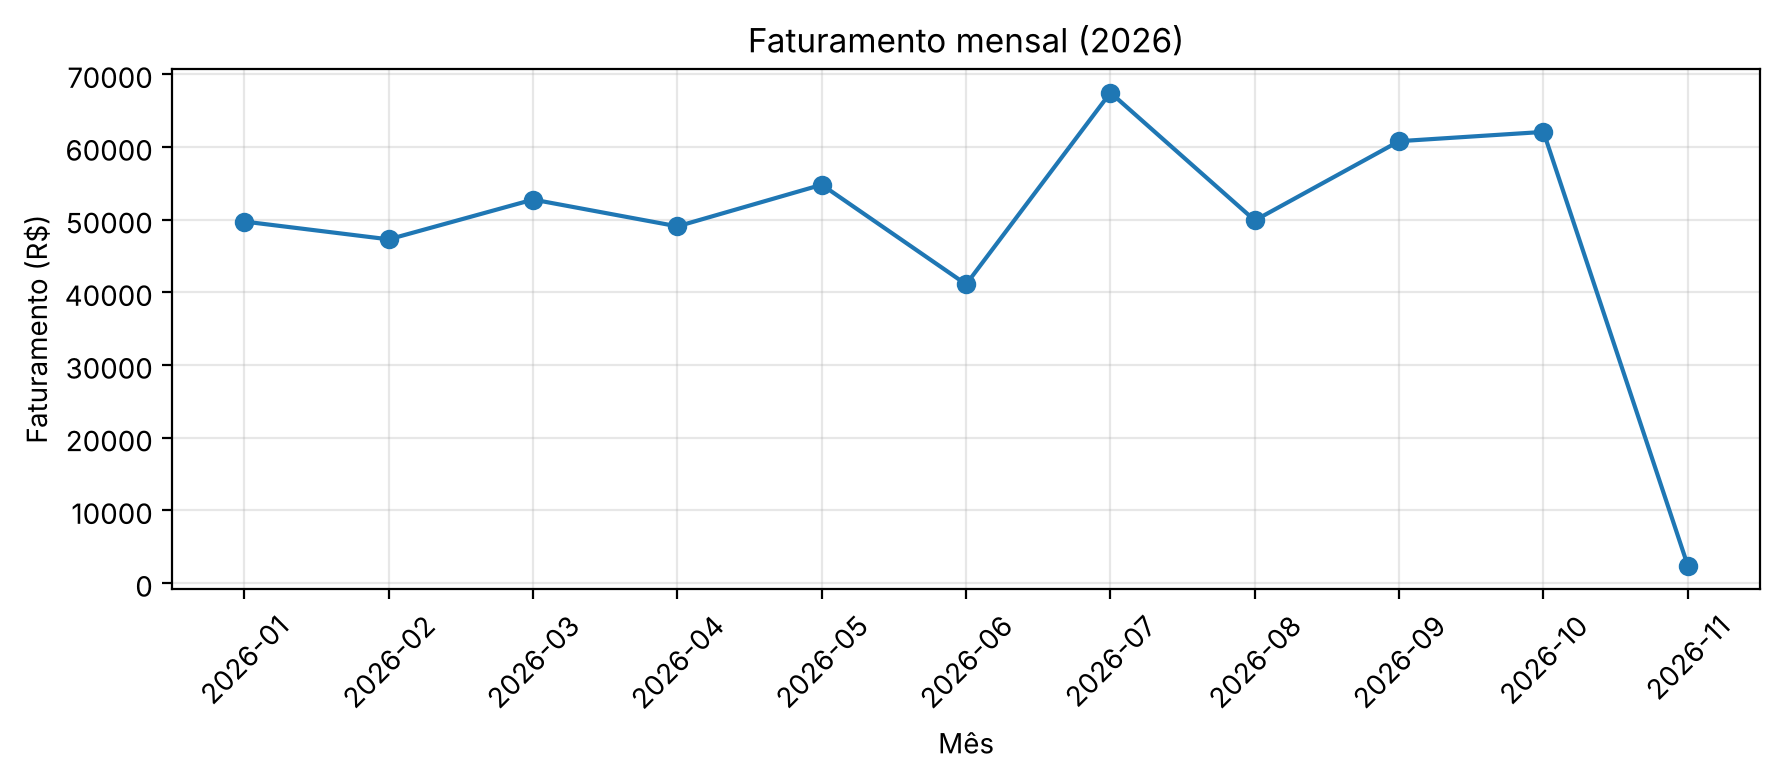

In [ ]:

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(fat_mensal.index.astype(str), fat_mensal.values, marker="o")
ax.set_title("Faturamento mensal (2026)")
ax.set_xlabel("Mês"); ax.set_ylabel("Faturamento (R$)")
ax.tick_params(axis="x", rotation=45); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

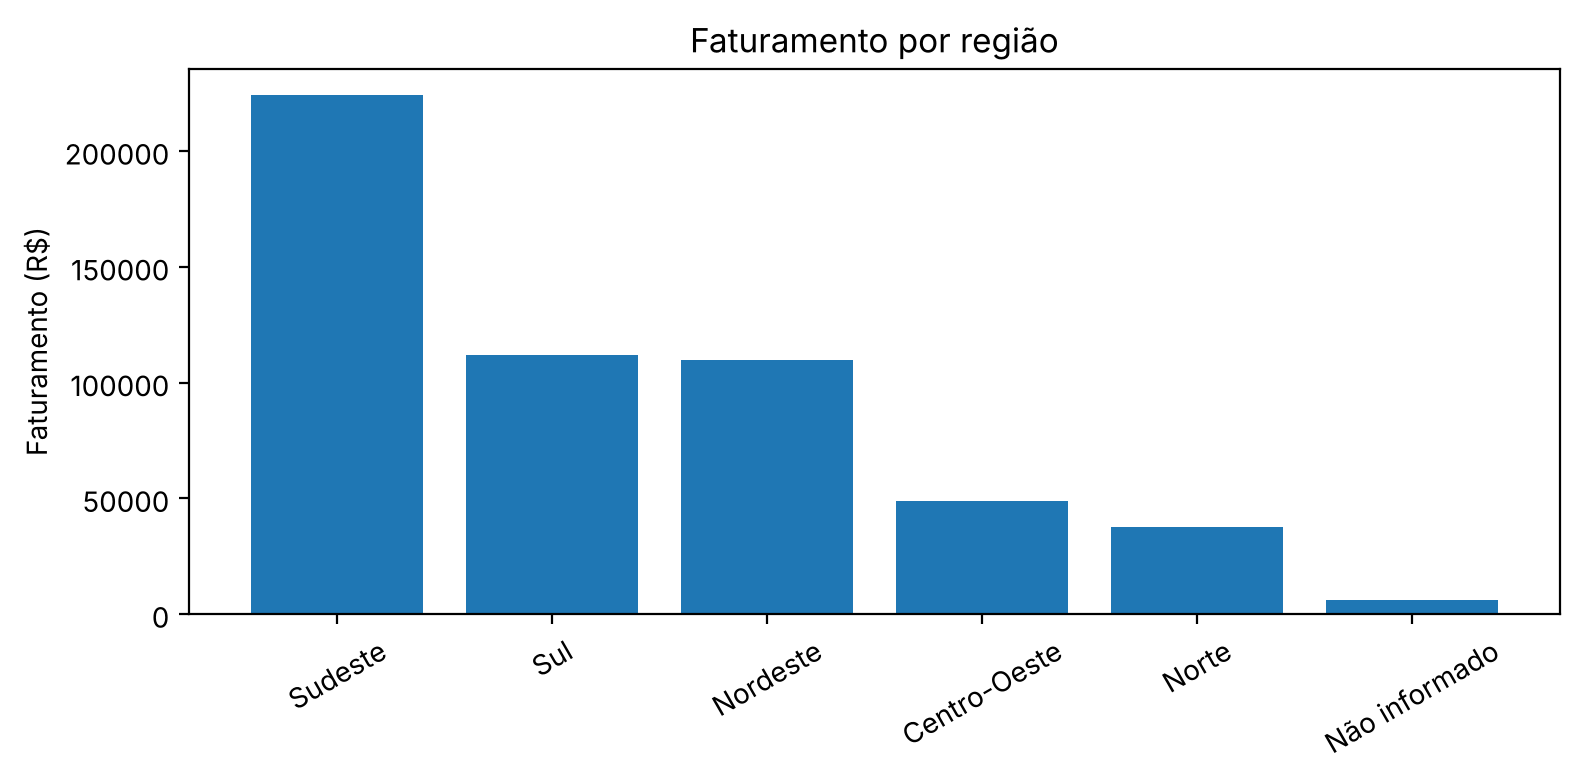

In [ ]:

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(fat_regiao.index, fat_regiao.values)
ax.set_title("Faturamento por região")
ax.set_ylabel("Faturamento (R$)")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [ ]:

resumo_regioes = (vendas_limpas.groupby("regiao")
                  .agg(faturamento_total=("valor_final", "sum"),
                       qtd_pedidos=("pedido_id", "nunique"),
                       qtd_itens=("quantidade", "sum"))
                  .round(2)
                  .sort_values("faturamento_total", ascending=False)
                  .reset_index())
resumo_regioes.to_csv("resultado/resumo_regioes.csv", index=False)
resumo_regioes

,regiao,faturamento_total,qtd_pedidos,qtd_itens
0,Sudeste,224237.71,513,980
1,Sul,112045.03,232,461
2,Nordeste,109791.40,231,455
3,Centro-Oeste,49052.77,111,216
4,Norte,37485.85,84,161
5,Não informado,6204.91,11,23


### Conclusão
O faturamento tratado soma cerca de R$ 538,8 mil em 1.182 pedidos válidos. O Sudeste lidera com folga (cerca de R$ 224 mil, mais de 40% do total), seguido por Sul e Nordeste, enquanto Norte e Centro-Oeste somam pouco. O Site é o canal de maior faturamento (cerca de R$ 274 mil), à frente do App e da Loja física. Pix é a forma de pagamento mais usada (491 pedidos), seguido de perto pelo cartão de crédito. Cadeira e Mesa são os produtos que mais faturam, o que mostra o peso de itens de ticket alto. O faturamento mensal oscila entre R$ 41 mil e R$ 67 mil, com pico em julho e queda em junho; novembro aparece quase zerado porque os dados cobrem apenas o primeiro dia do mês. A limpeza removeu 8 duplicatas e 10 registros inválidos e corrigiu valores incoerentes, então os números acima só são confiáveis depois desse tratamento.

## 4. PySpark DataFrame

In [21]:
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder
         .appName("trabalho_bigdata")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "4")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

df_spark = spark.read.csv("resultado/vendas_tratadas.csv", header=True, inferSchema=True)
df_spark.printSchema()

Picked up JAVA_TOOL_OPTIONS: -XX:+IgnoreUnrecognizedVMOptions -XX:-UseBASE64Intrinsics
Picked up JAVA_TOOL_OPTIONS: -XX:+IgnoreUnrecognizedVMOptions -XX:-UseBASE64Intrinsics


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/20 15:34:39 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/20 15:34:39 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/20 15:34:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


root
 |-- pedido_id: string (nullable = true)
 |-- data: date (nullable = true)
 |-- cliente_id: string (nullable = true)
 |-- categoria: string (nullable = true)
 |-- produto: string (nullable = true)
 |-- regiao: string (nullable = true)
 |-- canal: string (nullable = true)
 |-- forma_pagamento: string (nullable = true)
 |-- quantidade: integer (nullable = true)
 |-- preco_unitario: double (nullable = true)
 |-- desconto_percentual: integer (nullable = true)
 |-- valor: double (nullable = true)
 |-- frete: double (nullable = true)
 |-- avaliacao: double (nullable = true)
 |-- devolvido: string (nullable = true)
 |-- valor_esperado: double (nullable = true)
 |-- valor_incoerente: boolean (nullable = true)
 |-- valor_final: double (nullable = true)



In [22]:
resumo_spark = (df_spark
    .filter(F.col("valor_final") > 0)                       # transformação
    .groupBy("regiao")                                      # transformação (wide)
    .agg(F.round(F.sum("valor_final"), 2).alias("faturamento_total"),
         F.countDistinct("pedido_id").alias("qtd_pedidos"),
         F.sum("quantidade").alias("qtd_itens"))            # transformação
    .orderBy(F.desc("faturamento_total")))                  # transformação (wide)

resumo_spark.show()                                          # ACTION: dispara a execução

+-------------+-----------------+-----------+---------+
|       regiao|faturamento_total|qtd_pedidos|qtd_itens|
+-------------+-----------------+-----------+---------+
|      Sudeste|        224237.71|        513|      980|
|          Sul|        112045.03|        232|      461|
|     Nordeste|         109791.4|        231|      455|
| Centro-Oeste|         49052.77|        111|      216|
|        Norte|         37485.85|         84|      161|
|Não informado|          6204.91|         11|       23|
+-------------+-----------------+-----------+---------+



**Transformações:** `filter`, `groupBy`, `agg` e `orderBy`. Elas são *lazy*: apenas constroem o plano lógico, sem processar dados.

**Ação que dispara a execução:** `show()`. É ela que faz o Spark otimizar o plano e executar os jobs. (`count()`, `collect()` e `write` também seriam ações.)

**Por que `groupBy` exige redistribuição (shuffle)?** Linhas da mesma região estão espalhadas por várias partições, em vários executores. Para somar por região, todas as linhas de uma mesma chave precisam ir para a mesma partição. O Spark então reparticiona os dados por hash da chave pela rede, o que é uma transformação *wide* e geralmente a operação mais cara do job. O `orderBy` também causa shuffle, para ordenar globalmente.

## 5. Spark SQL

In [23]:
df_spark.createOrReplaceTempView("vendas")

consulta = spark.sql("""
    SELECT produto,
           categoria,
           SUM(quantidade)             AS itens_vendidos,
           ROUND(SUM(valor_final), 2)  AS faturamento
    FROM vendas
    WHERE devolvido = 'Não'
    GROUP BY produto, categoria
    ORDER BY itens_vendidos DESC
    LIMIT 10
""")
consulta.show(truncate=False)

+----------+-----------+--------------+-----------+
|produto   |categoria  |itens_vendidos|faturamento|
+----------+-----------+--------------+-----------+
|Ventilador|Casa       |109           |24461.58   |
|Carregador|Acessórios |107           |12372.78   |
|Mochila   |Escritório |103           |23644.45   |
|Cabo USB-C|Acessórios |101           |4765.75    |
|Aspirador |Casa       |100           |37453.64   |
|Microfone |Games      |98            |32780.56   |
|Cafeteira |Casa       |96            |19633.86   |
|Power bank|Acessórios |91            |16509.29   |
|SSD 1TB   |Eletrônicos|91            |39858.49   |
|Headset   |Eletrônicos|89            |16828.99   |
+----------+-----------+--------------+-----------+



Pergunta respondida: **quais são os 10 produtos mais vendidos em quantidade de itens, considerando apenas vendas não devolvidas?** É diferente da análise anterior, que olhava faturamento por região.

In [24]:
spark.stop()

## 6. HDFS e escalabilidade
- **NameNode:** guarda os metadados (árvore de diretórios, lista de blocos de cada arquivo e em quais DataNodes estão). Não armazena os dados em si e coordena leituras e escritas.
- **DataNodes:** armazenam fisicamente os blocos, atendem leituras e escritas dos clientes e reportam ao NameNode por heartbeats e block reports.
- **Sem heartbeat:** após um tempo limite, o NameNode marca o DataNode como morto e identifica os blocos que perderam réplicas. Ele então manda recriá-las em outros DataNodes até voltar ao fator 3.
- **Replicação e disponibilidade:** com 3 cópias de cada bloco em nós (e idealmente racks) diferentes, a perda de um nó ou rack não faz o dado ficar indisponível nem se perder. Leituras seguem pelas réplicas restantes. O custo é usar 3x o espaço (vários TB viram dezenas de TB em disco).

## 7. Auditoria de Machine Learning
**Problema: vazamento de dados (data leakage).** O `StandardScaler` foi ajustado (`fit_transform`) com **todo** o conjunto `X` *antes* do `train_test_split`. Assim, média e desvio-padrão incluem dados que deveriam ficar invisíveis ao modelo (o teste). A informação do teste vaza para o treino e a métrica fica otimista, sem refletir o desempenho em dados novos.

**Correção:** dividir primeiro e ajustar o scaler **só no treino**. Com `Pipeline`, isso acontece automaticamente (inclusive dentro de validação cruzada).

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X, y = make_classification(n_samples=500, n_features=8, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


modelo = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000)),
])
modelo.fit(X_train, y_train)
print("Acurácia no teste:", round(modelo.score(X_test, y_test), 3))

Acurácia no teste: 0.86
